# Building a Facial Recognition System

<p style="border-radius: 5px; background-color: #e0ebf5; color: #334451; padding: 10px 10px;" role="alert"><strong>IMPORTANT:</strong> Do not modify cells in this notebook unless instructed to do so.</p>

## About This Project

In this project, you will implement k-Nearest Neighbors (k-NN) to classify images of faces. You will use the NumPy library to implement functions that will find nearest neighbors, calculate absolute loss, perform k-NN classification on a data set, and calculate the accuracy of your classifier.

### Evaluation

**This project must be successfully completed and submitted in order to receive credit for this course. Your score on this project will be included in your final grade calculation.**
    
You are expected to write code where you see `# YOUR CODE HERE` within the cells of this notebook. Not all cells will be graded; code input cells followed by cells marked with `# Auto-graded test cell` will be graded. Upon submitting your work, the code you write at these designated positions will be assessed using an "auto-grader" that will run all test cells to assess your code. You will receive feedback from the auto-grader that will identify any errors in your code. Use this feedback to improve your code if you need to resubmit. Be sure not to change the names of any provided functions, classes, or variables within the existing code cells, as this will interfere with the auto-grader. Also, remember to execute all code cells sequentially, not just those you’ve edited, to ensure your code runs properly.
    
You can resubmit your work as many times as necessary before the submission deadline. If you experience difficulty or have questions about this exercise, use the Q&A discussion board to engage with your peers or seek assistance from the instructor.

Before starting your work, please review [eCornell's policy regarding plagiarism](https://s3.amazonaws.com/ecornell/global/eCornellPlagiarismPolicy.pdf) (the presentation of someone else's work as your own without source credit).

### Submit Code for Auto-Grader Feedback

Once you have completed your work on this notebook, you will submit your code for auto-grader review. Follow these steps:

1. **Save your notebook.**

2. **Mark as Completed** — In the blue menu bar along the top of this code exercise window, you’ll see a menu item called **Education**. In the **Education** menu, click **Mark as Completed** to submit your code for auto-grader/instructor review. This process will take a moment and a progress bar will show you the status of your submission.

3. **Review your results** — Once your work is marked as complete, the results of the auto-grader will automatically be presented in a new tab within the code exercise window. You can click on the assessment name in this feedback window to see more details regarding specific feedback/errors in your code submission.

4. **Repeat, if necessary** — The Jupyter Notebook will always remain accessible in the first tabbed window of the exercise. To reattempt the work, you will first need to click **Mark as Uncompleted** in the **Education** menu and then proceed to make edits to the notebook. Once you are ready to resubmit, follow steps one through three. You can repeat this procedure as many times as necessary.

You can also download a copy of this notebook in multiple formats using the **Save and Export Notebook As** option in the **File** menu above.

## Import Libraries

Before you get started, you need to import a few libraries. You can do this by executing the following code. Remember, run code in a cell by selecting the cell, holding the `Shift` key, and pressing `Enter`/`Return`.

In [2]:
import numpy as np
from scipy.stats import mode
from scipy.io import loadmat
import time

# Interactive plots
%matplotlib ipympl
import matplotlib.pyplot as plt

import sys
sys.path.append("/home/codio/workspace/.modules")
from helper import *

print("Python version:", sys.version.split(" ")[0])

Python version: 3.12.5


## k-Nearest Neighbors Implementation in Python

The goal of implementing your k-NN classifier is to build a classifier for face recognition. We have obtained some data, images of faces, for testing your code. The data resides in the file `faces.mat`, which holds the dataset for our exercises below.

We will refer to the training vectors as `xTr` with labels `yTr`. Our testing vectors are `xTe` with labels `yTe`. As a reminder, to predict the label or class of an image in `xTe`, we will look for the $k$-nearest neighbors in `xTr` and predict a label based on their labels in `yTr`. For evaluation, we will compare these labels against the true labels provided in `yTe`.

### Visualizing the Data

Let us take a look at the data. The following script will take the first ten training images from the face dataset and visualize them. Run the code cell to see the visualized data.

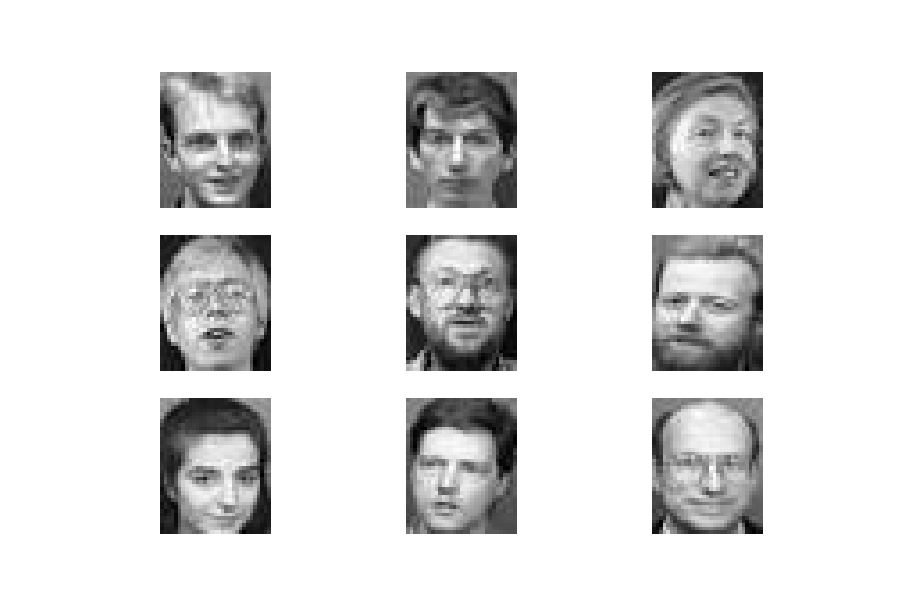

In [3]:
xTr, yTr, xTe, yTe = loaddata("faces.mat")

plt.figure(figsize=(9, 6))
plotfaces(xTr[:9, :])

The following four project parts will step you through implementing each function necessary to build your facial recognition system.

## Part One: Implement `findknn` [Graded]

Implement the function **`findknn`**, which should find the $k$ nearest neighbors ($k \leq n$) of a set of vectors within a given training data set. With `xTr` of size $n \times d$ and `xTe` of size $m \times d$, the call of:

```Python
(I, D) = findknn(xTr, xTe, k)
```

should result in two matrices `I` and `D`, both of dimensions $k\times m$, where $m$ is the number of input vectors in `xTe`. The matrix `I[i, j]` is the index of the $i$-th nearest neighbor of the vector `xTe[j, :]`.

So, for example, if we set `i = I(1, 3)`, then `xTr[i, :]` is the first nearest neighbor of vector `xTe[3, :]`. The second matrix `D` returns the corresponding distances. So `D[i, j]` is the distance of `xTe[j, :]` to its $i$-th nearest neighbor.

`l2distance(X, Z)` from the last exercise is readily available to you with the following specification:

```Python
"""
Computes the Euclidean distance matrix.

Syntax: D = l2distance(X, Z); or you can call l2distance with
        only one input, e.g., l2distance(X) = l2distance(X, X).
Input:
    X: nxd data matrix with n vectors (rows) of dimensionality d
    Z: mxd data matrix with m vectors (rows) of dimensionality d    
Output:
    D: nxm matrix of distances, where each entry D(i, j) is
       the Euclidean distance between X(i, :) and Z(j, :)

"""
```

One way to use `l2distance` is as follows:

1. Compute distances `D` between `xTr` and `xTe` using `l2distance`

2. Get indices of the `k` smallest distances for each testing point to create the `I` matrix

3. Use `I` to re-order `D` or create `D` by getting the `k`-smallest distances for each testing point

You may find [np.argsort(D, axis=0)](https://docs.scipy.org/doc/numpy/reference/generated/numpy.argsort.html) and [np.sort(D, axis=0)](https://docs.scipy.org/doc/numpy/reference/generated/numpy.sort.html) useful when implementing `findknn`.

In [4]:
def findknn(xTr, xTe, k):
    """
    Finds the k-nearest neighbors of xTe in xTr.
    
    Syntax: (I, D) = findknn(xTr, xTe, k)

    Input:
        xTr: nxd input matrix with n row-vectors of dimensionality d
        xTe: mxd input matrix with m row-vectors of dimensionality d
        k: Number of nearest neighbors to be found

    Output:
        I: kxm matrix of indices, where I(i, j) is the i-th nearest neighbor of xTe(j, :)
        D: kxm matrix of Euclidean distances to the respective k-nearest neighbors
    """
    I = None
    D = None
    
    # YOUR CODE HERE
    # calc L2 dist
    n, _ = xTr.shape
    m, _ = xTe.shape
    S = np.repeat(np.sum(xTr**2, axis=1).reshape(-1,1),m,axis=1)
    R = np.repeat(np.sum(xTe**2, axis=1).reshape(1,-1),n,axis=0)
    G = xTr @ xTe.T
    D2 = (S + R - 2*G)
    d = np.sqrt(np.maximum(D2,0))
    I = np.argsort(d, axis=0)[:k]
    D = np.sort(d, axis=0)[:k]
    # END OF YOUR CODE
    
    return I, D

Run the following self-test cell to check your implementation of `findknn`.

In [5]:
def findknn_test1():
    """
    Check that your findknn function output has the correct types
    """
    xTr = np.random.rand(500, 10)  # 500 random training data points
    xTe = np.random.rand(300, 10)  # 300 random testing data points

    # Compute indices and distances to the 5-nearest neighbors
    Ig, Dg = findknn(xTr, xTe, 5)  
    
    # Check if Ig is a matrix of integers, Dg a matrix of floats
    result = (
        isinstance(Ig, np.ndarray)
        and isinstance(Ig, np.ndarray)
        and (isinstance(Dg[0][0], np.float64) or isinstance(Dg[0][0], np.float32))
        and (isinstance(Dg[0][0], np.float64) or isinstance(Dg[0][0], np.float32))
    )
    
    return result


def findknn_test2():
    """
    Check that your findknn function output has the correct shape
    """
    xTr = np.random.rand(500, 10)  # 500 random training data points
    xTe = np.random.rand(300, 10)  # 300 random testing data points
    
    # Compute indices and distances to the 5-nearest neighbors
    Ig, Dg = findknn(xTr, xTe, 5)

    # Check if output shape is correct
    result = Ig.shape == (5, 300) and Dg.shape == (5, 300)
    
    return result


def findknn_test3():
    """
    Check the accuracy of your findknn function for 1-NN
    """
    np.random.seed(1)              # Set random seed for consistency
    xTr = np.random.rand(500, 10)  # 500 random training data points
    xTe = np.random.rand(300, 10)  # 300 random testing data points
    
    # Compute indices and distances to the nearest neighbors with *your* code
    Ig, Dg = findknn(xTr, xTe, 1)  
    
    # Compute indices and distances to the nearest neighbors with *our* code
    Is, Ds = findknn_grader(xTr, xTe, 1)

    # Compute the difference between your output and our output
    result = np.linalg.norm(Ig - Is) + np.linalg.norm(Dg - Ds)
    
    return result < 1e-5


def findknn_test4():
    """
    Check the accuracy of your findknn function for 3-NN
    """
    np.random.seed(2)              # Set random seed for consistency
    xTr = np.random.rand(500, 10)  # 500 random training data points
    xTe = np.random.rand(300, 10)  # 300 random testing data points
    
    # Compute indices and distances to the nearest neighbors with *your* code
    Ig, Dg = findknn(xTr, xTe, 3)  
    
    # Compute indices and distances to the nearest neighbors with *our* code
    Is, Ds = findknn_grader(xTr, xTe, 3)

    # Compute the difference between your output and our output
    result = np.linalg.norm(Ig - Is) + np.linalg.norm(Dg - Ds)
    
    return result < 1e-5


runtest(findknn_test1, "findknn_test1")
runtest(findknn_test2, "findknn_test2")
runtest(findknn_test3, "findknn_test3")
runtest(findknn_test4, "findknn_test4")

Running Test: findknn_test1 ... ✔ Passed!
Running Test: findknn_test2 ... ✔ Passed!
Running Test: findknn_test3 ... ✔ Passed!
Running Test: findknn_test4 ... ✔ Passed!


Skip over the auto-graded test cells below (see [Evaluation](#Evaluation) for details).

In [6]:
# Auto-graded test cell worth one point (findknn_test1)

In [7]:
# Auto-graded test cell worth one point (findknn_test2)

In [8]:
# Auto-graded test cell worth one point (findknn_test3)

In [9]:
# Auto-graded test cell worth one point (findknn_test4)

The following demo samples random points in 2D. If your `findknn` function is correctly implemented, you should be able to click anywhere on the plot to add a test point. The function should then draw direct connections from your test point to the $k$-nearest neighbors. Verify manually if your code is correct.

**Instructions:**

1. Run the cell below

2. To add a test point, click anywhere in the graph 

3. To increase $k$, hold down the `Shift` key and click anywhere in the graph

4. To decrease $k$, hold down the `Control` key and click anywhere in the graph

Please keep in mind:
1. Run (or rerun) this cell to interact with the plot.
2. Start the interactive demo by clicking the graph.
3. Test points are not added to the training dataset.


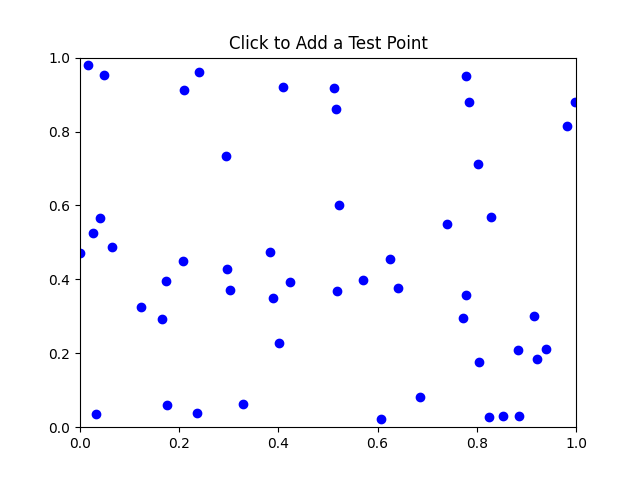

In [10]:
k_demo1 = 5                        # Number of neighbors for this demo
N = 50                             # Number of training points
train_data = np.random.rand(N, 2)  # Random training dataset


def onclick(event):
    global k_demo1, train_data
    
    # Get coordinates of the test point
    if event.key == None:
        test_point = np.array([[event.xdata, event.ydata]])
        test_point_x = test_point[0, 0]  # x-coordinate of test point
        test_point_y = test_point[0, 1]  # y-coordinate of test point
        plt.scatter(test_point_x, test_point_y, color="red", marker="o")

    if event.key == "shift" and k_demo1 < N - 1:
        k_demo1 += 1

    if event.key == "control" and k_demo1 > 1:
        k_demo1 -= 1
        
    # Find k-nearest neighbors and get their indices
    indices, _ = findknn(train_data, test_point, k_demo1)

    # Add coordinates of the test point and k-nearest neighbors
    x_coords = []  # Initialize list of x-coordinates
    y_coords = []  # Initialize list of y-coordinates
    for i in range(k_demo1):
        x_coords.append(test_point_x)                  # x-coordinate of test point
        x_coords.append(train_data[indices[i, 0], 0])  # x-coordinate of neighboring point
        x_coords.append(None)                          # No x-coordinate (separator)
        y_coords.append(test_point_y)                  # y-coordinate of test point
        y_coords.append(train_data[indices[i, 0], 1])  # y-coordinate of neighboring point
        y_coords.append(None)                          # No y-coordinate (separator)

    # Plot the test point and k-nearest neighbors
    plt.plot(x_coords, y_coords, color="red", linestyle="-")
    if k_demo1 == 1:
        plt.title(f"{k_demo1}-Nearest Neighbor (Click to Add Another Test Point)")
    else:
        plt.title(f"{k_demo1}-Nearest Neighbors (Click to Add Another Test Point)")
    plt.show()


print("Please keep in mind:")
print("1. Run (or rerun) this cell to interact with the plot.")
print("2. Start the interactive demo by clicking the graph.")
print("3. Test points are not added to the training dataset.")
fig = plt.figure()
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.scatter(train_data[:, 0], train_data[:, 1], color="b", marker="o")
plt.title(f"Click to Add a Test Point")
cid = fig.canvas.mpl_connect("button_press_event", onclick)

We can visualize the $k=3$ nearest training neighbors of some of the test points (click on the image to cycle through different test points).

Click on the images below to cycle through the test images.


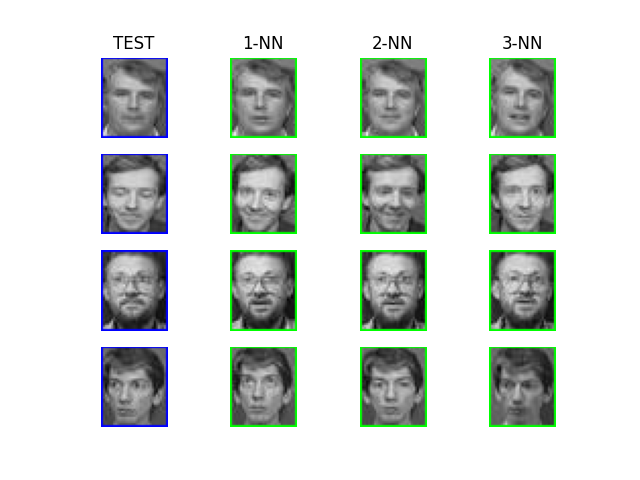

In [12]:
visualize_knn_images(findknn, imageType="faces")

## Part Two: Implement `accuracy` [Graded]

The function **`accuracy`** should compute the accuracy of a classifier.

The call

```Python
result = accuracy(truth, preds)
```

should output the **accuracy** in variable `result`. The input variables `truth` and `preds` should contain vectors of true and predicted labels respectively.

For example, the call:

```Python
accuracy([1, 2, 1, 2], [1, 2, 1, 1])
```

should return an accuracy of 0.75. Here, the true labels are `[1, 2, 1, 2]` and the predicted labels are `[1, 2, 1, 1]`. So the first three examples are classified correctly, and the last one is wrong (75% accuracy). You may find the following functions helpful: `flatten()`, `np.mean()`, and `np.abs()`.

In [13]:
def accuracy(truth, preds):
    """
    Analyzes the accuracy of a prediction against the ground truth

    Input:
        truth: n-dimensional vector of true class labels
        preds: n-dimensional vector of predictions

    Output:
        accur: Percent of predictions that are correct (a scalar)
    """
    accur = None
    
    # YOUR CODE HERE
    truth = truth.flatten()
    predictions = preds.flatten()
    accur = np.mean(truth == predictions)
    # END OF YOUR CODE
    
    return accur

Run the next cell to check your implementation of `accuracy`.

In [14]:
def accuracy_test1():
    """
    Check that your accuracy function has the correct output type
    """
    truth = np.array([1, 2, 3, 4])
    preds = np.array([1, 2, 3, 0])
    result = isinstance(accuracy(truth, preds), np.float64)
    return result


def accuracy_test2():
    """
    Check your accuracy function on 4-sample data
    """
    truth = np.array([1, 2, 3, 4])
    preds = np.array([1, 2, 3, 0])
    return abs(accuracy(truth, preds) - 0.75) < 1e-10


def accuracy_test3():
    """
    Check your accuracy function on random data
    """
    np.random.seed(1)                         # Random seed for consistency
    p1 = np.random.rand(1, 1000)              # Random samples
    truth = np.int16(p1 > 0.5)                # Random string of 0s and 1s
    p2 = p1 + np.random.randn(1, 1000) * 0.1  # Add a little noise to p1
    preds = np.int16(p2 > 0.5)                # Very similar to truth
    diff = abs(accuracy(truth, preds) - accuracy_grader(truth, preds))
    return diff < 1e-10                       # Difference should be small


runtest(accuracy_test1, "accuracy_test1 (types)")
runtest(accuracy_test2, "accuracy_test2 (exactness)")
runtest(accuracy_test3, "accuracy_test3 (exactness)")

Running Test: accuracy_test1 (types) ... ✔ Passed!
Running Test: accuracy_test2 (exactness) ... ✔ Passed!
Running Test: accuracy_test3 (exactness) ... ✔ Passed!


Skip over the auto-graded test cells below (see [Evaluation](#Evaluation) for details).

In [15]:
# Auto-graded test cell worth one point (accuracy_test1)

In [16]:
# Auto-graded test cell worth one point (accuracy_test2)

In [17]:
# Auto-graded test cell worth one point (accuracy_test3)

## Part Three: Implement `knnclassifier` [Graded]

Implement the function **`knnclassifier`**, which should perform `k`-nearest neighbor classification on a given test data set.

The call

```Python
preds = knnclassifier(xTr, yTr, xTe, k)
```

should output the predictions for the data in `xTe`, i.e. `preds[i]` will contain the prediction for `xTe[i, :]`.

You may find it helpful to use `flatten()` in the implementation of this function. It will also be useful to  refer back to the mode function you implemented Additional NumPy Exercises.

In [18]:
def knnclassifier(xTr, yTr, xTe, k):
    """
    Function that returns predictions from k-NN classifier

    Input:
        xTr: nxd input matrix with n row-vectors of dimensionality d
        yTr: n-dimensional vector of labels
        xTe: mxd input matrix with m row-vectors of dimensionality d
        k: Number of nearest neighbors to be found

    Output:
        preds: Predicted labels; i.e., preds[i] is the predicted label of xTe[i, :]
    """
    preds = None
    yTr = yTr.flatten()

    # YOUR CODE HERE
    from scipy.stats import mode as calc_mode
    I, D = findknn(xTr, xTe, k)
    neighbors = yTr[I]
    preds = np.zeros(xTe.shape[0])
    for i in range(xTe.shape[0]):
        preds[i] = calc_mode(neighbors[:,i], keepdims=False).mode
    # END OF YOUR CODE

    return preds

Run the next cell to check your implementation of `knn_classifier`.

In [19]:
def knn_classifier_test1():
    X = np.array([[1, 0, 0, 1], [0, 1, 0, 1]]).T
    y = np.array([1, 1, 2, 2])
    preds = knnclassifier(X, y, X, 1)
    return isinstance(preds, np.ndarray) and preds.shape == (4,)


def knn_classifier_test2():
    X = np.array([[1, 0, 0, 1], [0, 1, 0, 1]]).T
    y = np.array([1, 1, 2, 2])
    return np.array_equal(knnclassifier(X, y, X, 1), y)


def knn_classifier_test3():
    X = np.array([[1, 0, 0, 1], [0, 1, 0, 1]]).T
    y = np.array([1, 1, 2, 2])
    y2 = np.array([2, 2, 1, 1])
    return np.array_equal(knnclassifier(X, y, X, 3), y2)


def knn_classifier_test4():
    X = np.array([[-4, -3, -2, 2, 3, 4]]).T
    y = np.array([1, 1, 1, 2, 2, 2])
    X2 = np.array([[-1, 1]]).T
    y2 = np.array([1, 2])
    return np.array_equal(knnclassifier(X, y, X2, 2), y2)


def knn_classifier_test5():
    X = np.array([[-4, -3, -2, 2, 3, 4]]).T
    y = np.array([1, 1, 1, 2, 2, 2])
    X2 = np.array([[0, 1]]).T
    y2 = np.array([1, 2])
    y3 = np.array([2, 2])
    result1 = np.array_equal(knnclassifier(X, y, X2, 2), y2)
    result2 = np.array_equal(knnclassifier(X, y, X2, 2), y3)
    return result1 or result2


def knn_classifier_test6():
    np.random.seed(1)
    X = np.random.rand(4, 4)
    y = np.array([1, 2, 2, 2])
    return accuracy(knnclassifier(X, y, X, 1), y) == 1


def knn_classifier_test7():
    np.random.seed(2)
    X = np.random.rand(4, 4)
    y = np.array([1, 2, 1, 2])
    return accuracy(knnclassifier(X, y, X, 1), y) == 1


def knn_classifier_test8():
    np.random.seed(3)
    X = np.random.rand(10, 100)
    y = np.round(np.random.rand(10)).astype("int")
    return accuracy(knnclassifier(X, y, X, 1), y) == 1


runtest(knn_classifier_test1, "knn_classifier_test1")
runtest(knn_classifier_test2, "knn_classifier_test2")
runtest(knn_classifier_test3, "knn_classifier_test3")
runtest(knn_classifier_test4, "knn_classifier_test4")
runtest(knn_classifier_test5, "knn_classifier_test5")
runtest(knn_classifier_test6, "knn_classifier_test6")
runtest(knn_classifier_test7, "knn_classifier_test7")
runtest(knn_classifier_test8, "knn_classifier_test8")

Running Test: knn_classifier_test1 ... ✔ Passed!
Running Test: knn_classifier_test2 ... ✔ Passed!
Running Test: knn_classifier_test3 ... ✔ Passed!
Running Test: knn_classifier_test4 ... ✔ Passed!
Running Test: knn_classifier_test5 ... ✔ Passed!
Running Test: knn_classifier_test6 ... ✔ Passed!
Running Test: knn_classifier_test7 ... ✔ Passed!
Running Test: knn_classifier_test8 ... ✔ Passed!


Skip over the auto-graded test cells below (see [Evaluation](#Evaluation) for details).

In [20]:
# Auto-graded test cell worth one point (knn_classifier_test1)

In [21]:
# Auto-graded test cell worth one point (knn_classifier_test2)

In [22]:
# Auto-graded test cell worth one point (knn_classifier_test3)

In [23]:
# Auto-graded test cell worth one point (knn_classifier_test4)

In [24]:
# Auto-graded test cell worth one point (knn_classifier_test5)

In [25]:
# Auto-graded test cell worth one point (knn_classifier_test6)

In [26]:
# Auto-graded test cell worth one point (knn_classifier_test7)

In [27]:
# Auto-graded test cell worth one point (knn_classifier_test8)

You can compute the actual classification error on the test set by calling
```python
yPreds = knnclassifier(xTr, yTr, xTe, 3)
accuracy(yTe, yPreds)
```

## Part Four: Calculate Accuracy [Ungraded]

The following script runs your $k$-nearest neighbor classifier over the faces and digits data set. The faces data set has 40 classes and the digits data set has 10. What classification accuracy would you expect from a random classifier?

In [28]:
# Load the face data
xTr, yTr, xTe, yTe = loaddata("faces.mat")

# Make predictions and calculate accuracy
k = 1                                    # Use 1-NN classification
t0 = time.time()                         # Record start time
preds = knnclassifier(xTr, yTr, xTe, k)  # Make predictions
result = accuracy(yTe, preds)            # Compute accuracy
t1 = time.time()                         # Record stop time

print(f"Using {k}-NN classification to perform facial recognition...")
print(
    f"You obtained {100 * result:.2f}% classification",
    f"acccuracy in {t1 - t0:.4f} seconds.",
)

Using 1-NN classification to perform facial recognition...
You obtained 95.83% classification acccuracy in 0.1345 seconds.


## k-NN Boundary Visualization

To help give you a visual understanding of how the k-NN boundary is affected by $k$ and the specific dataset, feel free to play around with the visualization below.

**Instructions:**

1. Run the cell below

2. To add a point with a positive label, click anywhere in the graph 

3. To add a point with a negative label, hold down the `N` key and click anywhere in the graph

4. To increase $k$, hold down the `Shift` key and click anywhere in the graph

5. To decrease $k$, hold down the `Control` key and click anywhere in the graph

Please keep in mind:
1. Run (or rerun) this cell to interact with the plot.
2. Start by clicking the graph to add a positive point.
3. There is a delay between adding points or changing k.


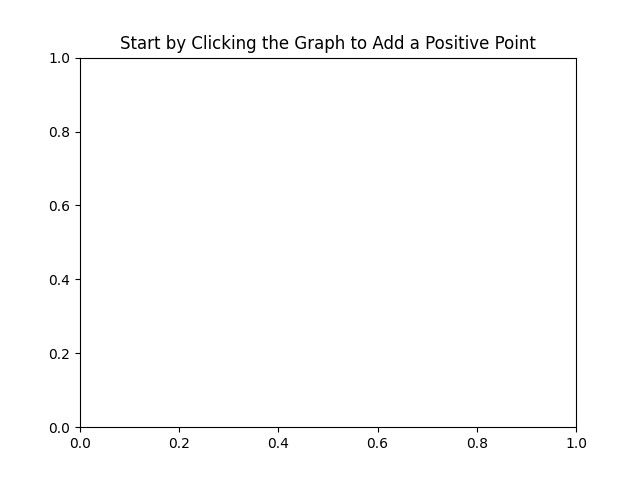

In [30]:
k_demo2 = 1
xy_data = np.empty((0, 2))
label_data = np.empty((0, 1))


def onclick_knn_classifier(event):
    global k_demo2, xy_data, label_data

    # Add positive point
    if event.key == None:
        label = 1
        point = np.array([event.xdata, event.ydata])
        xy_data = np.vstack((xy_data, point))
        label_data = np.append(label_data, label)

    # Add negative point
    if event.key == "n":
        label = -1
        point = np.array([event.xdata, event.ydata])
        xy_data = np.vstack((xy_data, point))
        label_data = np.append(label_data, label)
    
    # Increase `demo_k` by one
    if event.key == "shift" and k_demo2 < len(label_data) - 1:
        k_demo2 += 1
    
    # Decrease `demo_k` by one
    if event.key == "control" and k_demo2 > 1:
        k_demo2 -= 1

    RES = 50
    grid = np.linspace(0, 1, RES)
    X, Y = np.meshgrid(grid, grid)
    xTe = np.array([X.flatten(), Y.flatten()])
    Z = knnclassifier(xy_data, label_data, xTe.T, k_demo2)
    Z = Z.reshape(X.shape)
    Z[0, 0] = 1  # Optional: scale the colors correctly

    # Plot configuration
    plt.cla()                                  # Clear axes
    plt.xlim((0, 1))                           # x-axis limits
    plt.ylim((0, 1))                           # y-axis limits
    labels = ["$-1$", "$+1$"]                  # Labels for training points
    symbols = ["x", "o"]                       # "x" for -1 and "o" for +1 (training)
    mycolors = [[1, 0.5, 0.5], [0.5, 0.5, 1]]  # Red for -1 and blue for +1 (predictions)
    
    # Get the class values from training labels
    classvals = np.unique(label_data)

    # Plot prediction contours and data points
    if len(classvals) == 1 and 1 in classvals:
        # Plot blue prediction contours because only +1 points have been added
        plt.contourf(X, Y, np.sign(Z), colors=[[0.5, 0.5, 1], [0.5, 0.5, 1]])
        
        # Plot points with "o" markers because only +1 points have been added
        for idx, c in enumerate(classvals):
            plt.scatter(
                xy_data[label_data == c, 0],  # x-coordinate of training point
                xy_data[label_data == c, 1],  # y-coordinate of training point
                label="$+1$",                 # Label of training point
                marker="o",                   # Marker of training point
                color="black",                # Color of training point
            )
    else:
        # Plot prediction contours: red for -1 and blue for +1
        plt.contourf(X, Y, np.sign(Z), colors=mycolors)

        # Plot training data: "x" for -1 and "o" for +1
        for idx, c in enumerate(classvals):
            plt.scatter(
                xy_data[label_data == c, 0],  # x-coordinate of training point
                xy_data[label_data == c, 1],  # y-coordinate of training point
                label=labels[idx],            # Label of training point (-1 or +1)         
                marker=symbols[idx],          # Marker of training point ("x" or "o")
                color="black",                # Color of training point
            )
        
    plt.title(f"k-NN Classifier (k={k_demo2})")
    plt.legend(loc="upper left")
    plt.show()


# Interactive demo
print("Please keep in mind:")
print("1. Run (or rerun) this cell to interact with the plot.")
print("2. Start by clicking the graph to add a positive point.")
print("3. There is a delay between adding points or changing k.")
fig = plt.figure()
plt.title("Start by Clicking the Graph to Add a Positive Point")
plt.xlim(0, 1)
plt.ylim(0, 1)
cid = fig.canvas.mpl_connect("button_press_event", onclick_knn_classifier)